# GBP: recalibrating Dynamic BPS vs the LDF pool

In [2]:
%load_ext autoreload
%autoreload 2

import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm

from ldf import ldf_func
from pit import pit_func
from utils.utils import ex_tlp
from uniformity_tests import uniformity_test
from recal_dma_new import tvgas_pit_dma_new, convolution_recal_pit_dma_new
from recal_beta_dma_new import tvgas_pit_beta_dma_new, convolution_recal_pit_beta_dma_new
from localised_metrics import evaluate_localized
import bps
import sim_report as sr

sns.set_style("whitegrid")
sns.set_context("paper")
#plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Palatino"]})
OUT = Path("figures/fx"); OUT.mkdir(parents=True, exist_ok=True)

## 0. Settings

In [3]:
ccy      = "GBP"
time_ind = 362                  # evaluation window (last time_ind months), as in USD_AUD.ipynb

# ---- BPS (settings of the FX BPS run) --------------------------------------------------
BPS_DELTA  = (0.99, 0.99)       # [state discount delta, obs. variance discount beta]
C0_SCALE   = 0.297              # C_0 = C0_SCALE * I
S0         = None
N0         = 1 / (1 - BPS_DELTA[1])   # = 100
AGENT_DOF  = 1000.0             # the FX agents are Gaussian: a large t dof makes them (numerically) normal
BPS_MIN_TRAIN = 50             # months of data before the first BPS forecast (MATLAB: t = 50)
BURN_IN    = 3000
MCMC_ITER  = 8000
EXACT_PORT = True
N_JOBS     = -1                 # origins run in parallel
BPS_PATH   = f"results/bps_fx_{ccy}_{BURN_IN}_{MCMC_ITER}.pkl"     # cache: delete to rerun
# quick test first: BURN_IN, MCMC_ITER = 300, 500

# ---- LDF comparison ---------------------------------------------------------------------
LDF_DELTA  = 0.9

# ---- recalibration (as in USD_AUD.ipynb) ------------------------------------------------
warmup, eval_start, ALPHA = 0, 0, 0.95

## 1. Data

In [4]:
exchange_rate = pd.read_excel(r"data/Y.xlsx", header=0, engine="openpyxl")
exchange_rate.rename(columns={"Unnamed: 0": "Date"}, inplace=True)
exchange_rate["Date"] = pd.to_datetime(exchange_rate["Date"])
ccy_idx = exchange_rate.columns.get_loc(ccy) - 1

log_lik    = np.load(r"data/uip_l1_save_loglik.npz")["x"]
means      = np.load(r"data/uip_l1_save_means.npz")["x"]
covariance = np.load(r"data/uip_l1_save_covariance.npz")["x"]

# full history of the agents (K, T_all) and the outcome, aligned at the end as in USD_AUD.ipynb
mean_all = means[:, :, ccy_idx]
var_all  = covariance[:, :, ccy_idx, ccy_idx]
T_all    = mean_all.shape[1]
y_all    = exchange_rate[ccy].values[-T_all:].astype(float)
date_all = exchange_rate["Date"].values[-T_all:]
K = mean_all.shape[0]

time = exchange_rate["Date"][-time_ind:]
y    = exchange_rate[ccy][-time_ind:].values
aud_mean, aud_var = mean_all[:, -time_ind:], var_all[:, -time_ind:]
assert np.allclose(y, y_all[-time_ind:])
print(f"K = {K} agents, T_all = {T_all} months, evaluation window = last {time_ind}, "
      f"history before the window = {T_all - time_ind} months")

K = 32 agents, T_all = 362 months, evaluation window = last 362, history before the window = 0 months


## 2. LDF pool

In [6]:
discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])
c = 10 ** -20
res_ldf = ldf_func(log_lik.astype(float), levels=2, discount_factors=[discount_factors, discount_factors],
                   activation_functions=["softmax", "softmax"], c=c)
aud_weights = res_ldf["weights"][:, -time_ind:, :]

linear_pool = ex_tlp(aud_mean, aud_var, x_grid, aud_weights)      # (12, T, M)
TLP = pit_func(linear_pool, x_grid, y)                             # (12, T)

def gaussian_mixture_logscore(mean, var, weights, y):
    comp_pdf = norm.pdf(y[None, :], loc=mean, scale=np.sqrt(var))
    return np.log(np.clip(np.einsum("ptk,kt->pt", weights, comp_pdf), 1e-300, None))

logscore = gaussian_mixture_logscore(aud_mean, aud_var, aud_weights, y)   # (12, T)
d_idx = int(np.argmin(np.abs(discount_factors - LDF_DELTA)))

## 3. Dynamic BPS

In [7]:
%%time
BPS_START = max(BPS_MIN_TRAIN, T_all - time_ind)     # first forecast (0-based, in the agents' time axis)
prior = dict(m_0=np.r_[0.0, np.full(K, 1.0 / K)], C_0=C0_SCALE * np.eye(K + 1), n_0=N0, s_0=float(np.var(y_all[:BPS_START])))
if Path(BPS_PATH).exists():
    bps_out = pickle.load(open(BPS_PATH, "rb")); print("loaded", BPS_PATH)
else:
    bps_out = bps.run_bps(y_all, mean_all.T, var_all.T, np.full((T_all, K), AGENT_DOF), x_grid,
                          start=BPS_START, delta=BPS_DELTA, prior=prior,
                          burn_in=BURN_IN, mcmc_iter=MCMC_ITER, seed=42, n_jobs=N_JOBS,
                          exact_port=EXACT_PORT)
    pickle.dump(bps_out, open(BPS_PATH, "wb"))
print(f"BPS forecasts {len(bps_out['index'])} of the {time_ind} window months")

loaded bps_fx_GBP_3000_8000.pkl
BPS forecasts 312 of the 362 window months
CPU times: user 321 μs, sys: 1.93 ms, total: 2.25 ms
Wall time: 2.64 ms


In [8]:
print("min grid mass (BPS):", bps_out["grid_mass"].min().round(3))
print("sd of y:", y_all.std().round(4), "| var of first 50 months:", y_all[:50].var().round(6))
#print("s0 =", S0, "-> implied sd", np.sqrt(S0).round(3))

min grid mass (BPS): 1.0
sd of y: 0.0264 | var of first 50 months: 0.001414


In [9]:
# common window: the months BPS forecasts (drops the first months of the window if they were BPS training data)
off   = BPS_START - (T_all - time_ind)                       # offset into the time_ind window
y     = exchange_rate[ccy][-time_ind:].values[off:]           # re-run safe
dates = pd.to_datetime(time).reset_index(drop=True)[off:].reset_index(drop=True)
W     = slice(off, None)
print(f"common window: {dates.iloc[0]:%Y-%m} to {dates.iloc[-1]:%Y-%m}, {len(y)} months")

# both pools as (1, T, M) / (1, T) over the same window
POOLS = {
    "LDF": dict(cdfs=linear_pool[d_idx:d_idx + 1, W], pits=TLP[d_idx:d_idx + 1, W], log=logscore[d_idx:d_idx + 1, W],
                mean=(aud_mean * aud_weights[d_idx].T).sum(axis=0)[W], label=[float(LDF_DELTA)]),
    "BPS": dict(cdfs=bps_out["cdfs"], pits=pit_func(bps_out["cdfs"], x_grid, y), log=bps_out["log_pd"],
                mean=bps_out["mean"][0], label=[float(BPS_DELTA[0])]),
}
print("BPS: max |grid PIT - exact PIT| =", np.abs(POOLS["BPS"]["pits"] - bps_out["pits"]).max().round(4),
      "| min grid mass =", bps_out["grid_mass"].min().round(4))

common window: 1994-08 to 2020-07, 312 months
BPS: max |grid PIT - exact PIT| = 0.0 | min grid mass = 1.0


In [10]:
es = eval_start
rows = []
for name, P in POOLS.items():
    err = y[es:] - P["mean"][es:]
    rows.append({"pool": name, "RMSE": np.sqrt(np.mean(err ** 2)),
                 "mean log score": P["log"][0, es:].mean(), "cum. log score": P["log"][0, es:].sum(),
                 "KS": stats.kstest(P["pits"][0, es:], "uniform").statistic,
                 "KS p": stats.kstest(P["pits"][0, es:], "uniform").pvalue})
pd.DataFrame(rows).set_index("pool").round(4)          # evaluated from eval_start, like the recalibrators

,RMSE,mean log score,cum. log score,KS,KS p
pool,,,,,
LDF,0.0245,2.2693,708.0204,0.0559,0.2726
BPS,0.0243,2.1866,682.2234,0.1094,0.0010


LDF: 90% coverage 94.2%
BPS: 90% coverage 97.1%


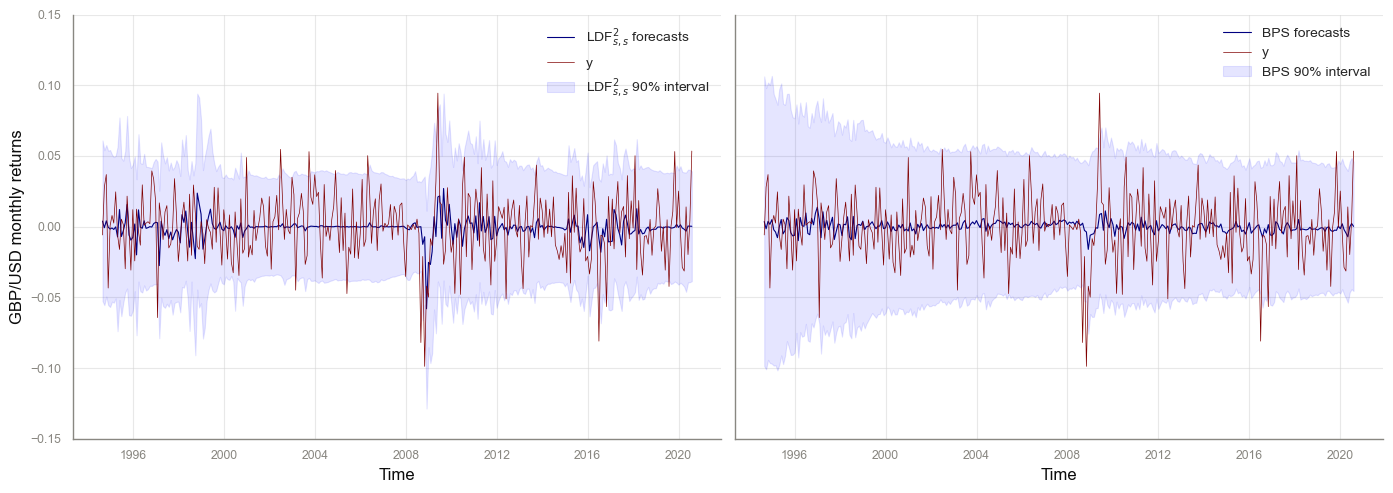

In [34]:
def pool_quantile(F, p, grid):
    return np.array([np.interp(p, F[t], grid) for t in range(F.shape[0])])

fig, axes = plt.subplots(1,2, figsize=(14, 5), sharex=True, sharey=True)
for ax, (name, P) in zip(axes, POOLS.items()):
    q05 = pool_quantile(P["cdfs"][0], 0.05, x_grid); q95 = pool_quantile(P["cdfs"][0], 0.95, x_grid)
    lab = r"LDF$^2_{s,s}$" if name == "LDF" else "BPS"
    ax.plot(dates, P["mean"], c="navy", lw=0.8, label=f"{lab} forecasts")
    ax.plot(dates, y, c="maroon", lw=0.5, label="y")
    ax.fill_between(dates, q05, q95, color="blue", alpha=0.1, label=f"{lab} 90% interval")
    ax.set_ylim(-0.15, 0.15)
    ax.legend(loc="upper right", fontsize=10,frameon=False)
    ax.set_xlabel("Time", fontsize=12)
    ax.grid(alpha=0.5, which="major", c="lightgrey")
    print(f"{name}: 90% coverage {np.mean((y[es:] >= q05[es:]) & (y[es:] <= q95[es:])):.1%}")
axes[0].set_ylabel(f"{ccy}/USD monthly returns", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "bps_vs_ldf_exchange_rate.pdf", dpi=600, bbox_inches="tight"); plt.show()

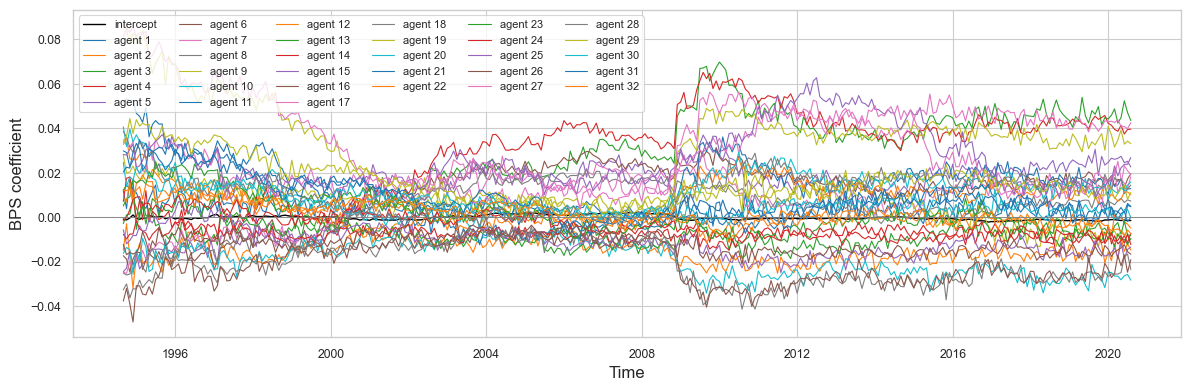

In [12]:
# BPS synthesis coefficients (posterior mean of theta_{t+1} at each origin)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates, bps_out["a_k"][:, 0], color="black", lw=1, label="intercept")
for j in range(K):
    ax.plot(dates, bps_out["a_k"][:, j + 1], lw=0.8, label=f"agent {j + 1}")
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Time", fontsize=12); ax.set_ylabel("BPS coefficient", fontsize=12)
ax.legend(fontsize=8, ncol=min(K + 1, 6), loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "bps_coefficients.png", dpi=300, bbox_inches="tight"); plt.show()

## 4. Recalibration of both pools (settings of `USD_AUD.ipynb`)

In [13]:
def recalibrate(P):
    common = dict(x=x_grid, y=y, pit_data=P["pits"], cdf_data=P["cdfs"], discount_factors=P["label"],
                  warmup=warmup, eval_start=eval_start, alpha=ALPHA)
    return dict(
        rg=tvgas_pit_dma_new(K=6, **common),
        rc=convolution_recal_pit_dma_new(K=6, refit_every=20, hidden_size=4, num_epochs=300,
                                         learning_rate=1e-3, seed=42, **common),
        bg=tvgas_pit_beta_dma_new(**common),
        bc=convolution_recal_pit_beta_dma_new(refit_every=20, hidden_size=4, num_epochs=300,
                                              learning_rate=1e-3, seed=42, **common))

RECAL = {name: recalibrate(P) for name, P in POOLS.items()}
index = 0          # one pool per method list


Two-timescale GAS (aggregated)  v = tau_GAS(u)  |  base: 0.9
  weights: identity=0.35  glacial=0.34  slow=0.21   (eff. 3.54 of 5; mass on fast filters 0.10; alpha=0.95, memory~20)
  EVALUATION [0,312)  n=312
     log-score total    -4.005   per obs -0.0128 (SE 0.0081)   t=-1.98  p=0.047
     oracle ceiling +0.0052/obs  -> captured -249%
     best single filter 'identity' -0.0000/obs; mixture -0.0128 vs it (no-harm floor, valid at alpha=1: -0.0052)
     static expanding map -0.0309/obs (KS 0.0296);  GAS - static +0.0181  t=+0.89  p=0.376
     90% interval  width 0.0895 -> 0.0859   coverage 0.942 -> 0.929   IS 0.1095 -> 0.1087 (t=+1.01)
     KS   0.0559 -> 0.0309   (null mean 0.0492)
     ECE  0.2051 -> 0.1410   CRPS 0.0138 -> 0.0138
     mean bias -0.0007 -> +0.0000
     PIT var by third  0.0686 0.0775 0.0724  ->  0.0733 0.0832 0.0782   (target 0.0833)

Composition  v = tau_GAS(tau_NN(u))  |  base: 0.9
  alpha=0.95 (memory~20), floor=0.001, step_norm=coord   eff. experts: raw bank 3.54

### Uniformity tests

In [15]:
TESTS = {}
for name, P in POOLS.items():
    TESTS[f"{name} raw"] = uniformity_test(P["pits"][:, eval_start:], discount_factors=P["label"])[1]
    for k, lab in [("rg", "RQS-GAS"), ("rc", "RQS-Con"), ("bg", "Beta-GAS"), ("bc", "Beta-Con")]:
        cal = np.vstack([r["calibrated_pits"] for r in RECAL[name][k]])
        TESTS[f"{name} {lab}"] = uniformity_test(cal, discount_factors=P["label"])[1]
pd.concat(TESTS)

,,Model,Tests_Passed,KS_Test,AD_Test,Chi2_Test,DH_Test,LB_Test,Berkowitz_Test,Mean_Test,Variance_Test,Coverage_5%_Test,Coverage_95%_Test,Efficiency_Test,Probabilistic_Calibration,Complete_Calibration
LDF raw,0,δ = 0.9,7/10,PASS,PASS,PASS,FAIL,FAIL,PASS,PASS,FAIL,PASS,PASS,N/A,Rejected,Rejected
LDF RQS-GAS,0,δ = 0.9,8/10,PASS,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Rejected,Rejected
LDF RQS-Con,0,δ = 0.9,8/10,PASS,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Rejected,Rejected
LDF Beta-GAS,0,δ = 0.9,7/10,PASS,PASS,PASS,FAIL,FAIL,FAIL,PASS,PASS,PASS,PASS,N/A,Rejected,Rejected
LDF Beta-Con,0,δ = 0.9,7/10,PASS,PASS,PASS,FAIL,FAIL,FAIL,PASS,PASS,PASS,PASS,N/A,Rejected,Rejected
BPS raw,0,δ = 0.99,2/10,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,PASS,FAIL,FAIL,FAIL,N/A,Rejected,Rejected
BPS RQS-GAS,0,δ = 0.99,10/10,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Not rejected
BPS RQS-Con,0,δ = 0.99,9/10,PASS,PASS,PASS,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,N/A,Not rejected,Not rejected
BPS Beta-GAS,0,δ = 0.99,6/10,PASS,PASS,PASS,FAIL,FAIL,FAIL,PASS,FAIL,PASS,PASS,N/A,Rejected,Rejected
BPS Beta-Con,0,δ = 0.99,8/10,PASS,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Rejected,Rejected


In [16]:
def tests_passed_latex(tables, caption="Number of tests passed for each method",
                       label="tab:tests-passed"):
    """tables: {row label: test-result DataFrame}. Counts the rows marked PASS in each test column."""
    cols = [("KS_Test", "KS"), ("AD_Test", "AD"), ("Chi2_Test", r"$\chi^2$"),
            ("DH_Test", "DH"), ("LB_Test", "LB"), ("Berkowitz_Test", "Berkowitz")]
    lines = [r"\begin{table}[H]", r"\centering", r"\onehalfspacing", r"\small",
             r"\begin{tabular}{l " + "c " * len(cols) + "}", r"\toprule",
             " & " + " & ".join(h for _, h in cols) + r" \\", r"\midrule"]
    for name, df in tables.items():
        counts = [int(df[c].astype(str).str.strip().str.upper().eq("PASS").sum()) for c, _ in cols]
        lines.append(f"{name} & " + " & ".join(map(str, counts)) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}",
              rf"\label{{{label}}}", r"\end{table}"]
    print("\n".join(lines))

tests_passed_latex(TESTS, caption="Uniformity / independence tests passed (FX): LDF vs BPS, before and after recalibration",
                   label="tab:tests-bps-ldf-fx")

\begin{table}[H]
\centering
\onehalfspacing
\small
\begin{tabular}{l c c c c c c }
\toprule
 & KS & AD & $\chi^2$ & DH & LB & Berkowitz \\
\midrule
LDF raw & 1 & 1 & 1 & 0 & 0 & 1 \\
LDF RQS-GAS & 1 & 1 & 1 & 0 & 0 & 1 \\
LDF RQS-Con & 1 & 1 & 1 & 0 & 0 & 1 \\
LDF Beta-GAS & 1 & 1 & 1 & 0 & 0 & 0 \\
LDF Beta-Con & 1 & 1 & 1 & 0 & 0 & 0 \\
BPS raw & 0 & 0 & 0 & 0 & 1 & 0 \\
BPS RQS-GAS & 1 & 1 & 1 & 1 & 1 & 1 \\
BPS RQS-Con & 1 & 1 & 1 & 1 & 1 & 1 \\
BPS Beta-GAS & 1 & 1 & 1 & 0 & 0 & 0 \\
BPS Beta-Con & 1 & 1 & 1 & 0 & 0 & 1 \\
\bottomrule
\end{tabular}
\caption{Uniformity / independence tests passed (FX): LDF vs BPS, before and after recalibration}
\label{tab:tests-bps-ldf-fx}
\end{table}


### PIT ECDF

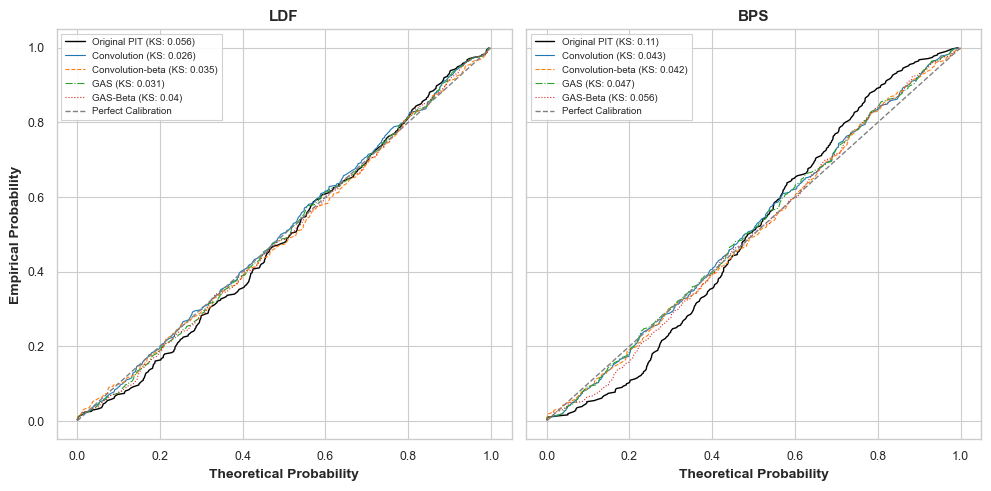

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, (name, P) in zip(axes, POOLS.items()):
    R = RECAL[name]
    pit_example = P["pits"][index, warmup:]
    ecdf = np.arange(1, len(pit_example) + 1) / len(pit_example)
    ax.plot(np.sort(pit_example), ecdf, color="black", lw=1,
            label=f"Original PIT (KS: {R['rc'][index]['ks_before']:.2g})")
    for k, lab, col, ls in [("rc", "Convolution", "#1f77b4", "-"), ("bc", "Convolution-beta", "#ff7f0e", "--"),
                            ("rg", "GAS", "#2ca02c", "-."), ("bg", "GAS-Beta", "#d62728", ":")]:
        ax.plot(np.sort(R[k][index]["calibrated_pits"]), ecdf, color=col, linestyle=ls, lw=0.8,
                label=f"{lab} (KS: {R[k][index]['ks_after']:.2g})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect Calibration", lw=1)
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Theoretical Probability", fontsize=10, fontweight="bold")
    ax.legend(fontsize=7, loc="upper left", frameon=True, framealpha=0.9, edgecolor="0.8", fancybox=False)
axes[0].set_ylabel("Empirical Probability", fontsize=10, fontweight="bold")
plt.tight_layout(); fig.savefig(OUT / "bps_vs_ldf_ecdf.png", dpi=300, bbox_inches="tight"); plt.show()

### Cumulative log-score gain over the raw pool

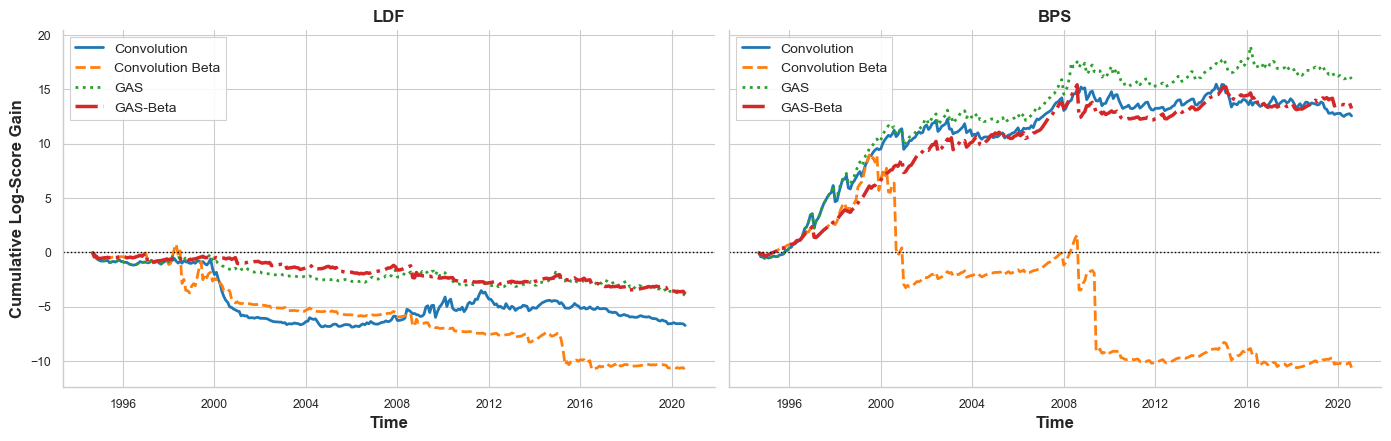

,LDF,BPS
mean log-score gain,,
GAS,-0.0128,0.0512
GAS-Beta,-0.0123,0.0425
Convolution Beta,-0.0349,-0.0340
Convolution,-0.0216,0.0403


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, POOLS):
    R = RECAL[name]
    for k, lab, col, ls, lw in [("rc", "Convolution", "#1f77b4", "-", 2), ("bc", "Convolution Beta", "#ff7f0e", "--", 2),
                                ("rg", "GAS", "#2ca02c", ":", 2), ("bg", "GAS-Beta", "#d62728", "-.", 2.5)]:
        ax.plot(dates[warmup:], np.cumsum(np.asarray(R[k][index]["log_likelihood"])[warmup:]),
                label=lab, color=col, linestyle=ls, linewidth=lw)
    ax.axhline(y=0, color="black", linestyle=":", linewidth=1)
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Time", fontsize=12, fontweight="bold")
    ax.legend(fontsize=10, loc="upper left", frameon=True, framealpha=0.9, edgecolor="0.8", fancybox=False)
axes[0].set_ylabel("Cumulative Log-Score Gain", fontsize=12, fontweight="bold")
sns.despine(trim=False); plt.tight_layout()
fig.savefig(OUT / "bps_vs_ldf_cum_gain.png", dpi=300, bbox_inches="tight"); plt.show()

pd.DataFrame({name: {lab: np.mean(np.asarray(RECAL[name][k][index]["log_likelihood"])[eval_start:])
                     for k, lab in [("rg", "GAS"), ("bg", "GAS-Beta"), ("bc", "Convolution Beta"), ("rc", "Convolution")]}
              for name in POOLS}).round(4).rename_axis("mean log-score gain")

### Raw vs recalibrated 90% intervals

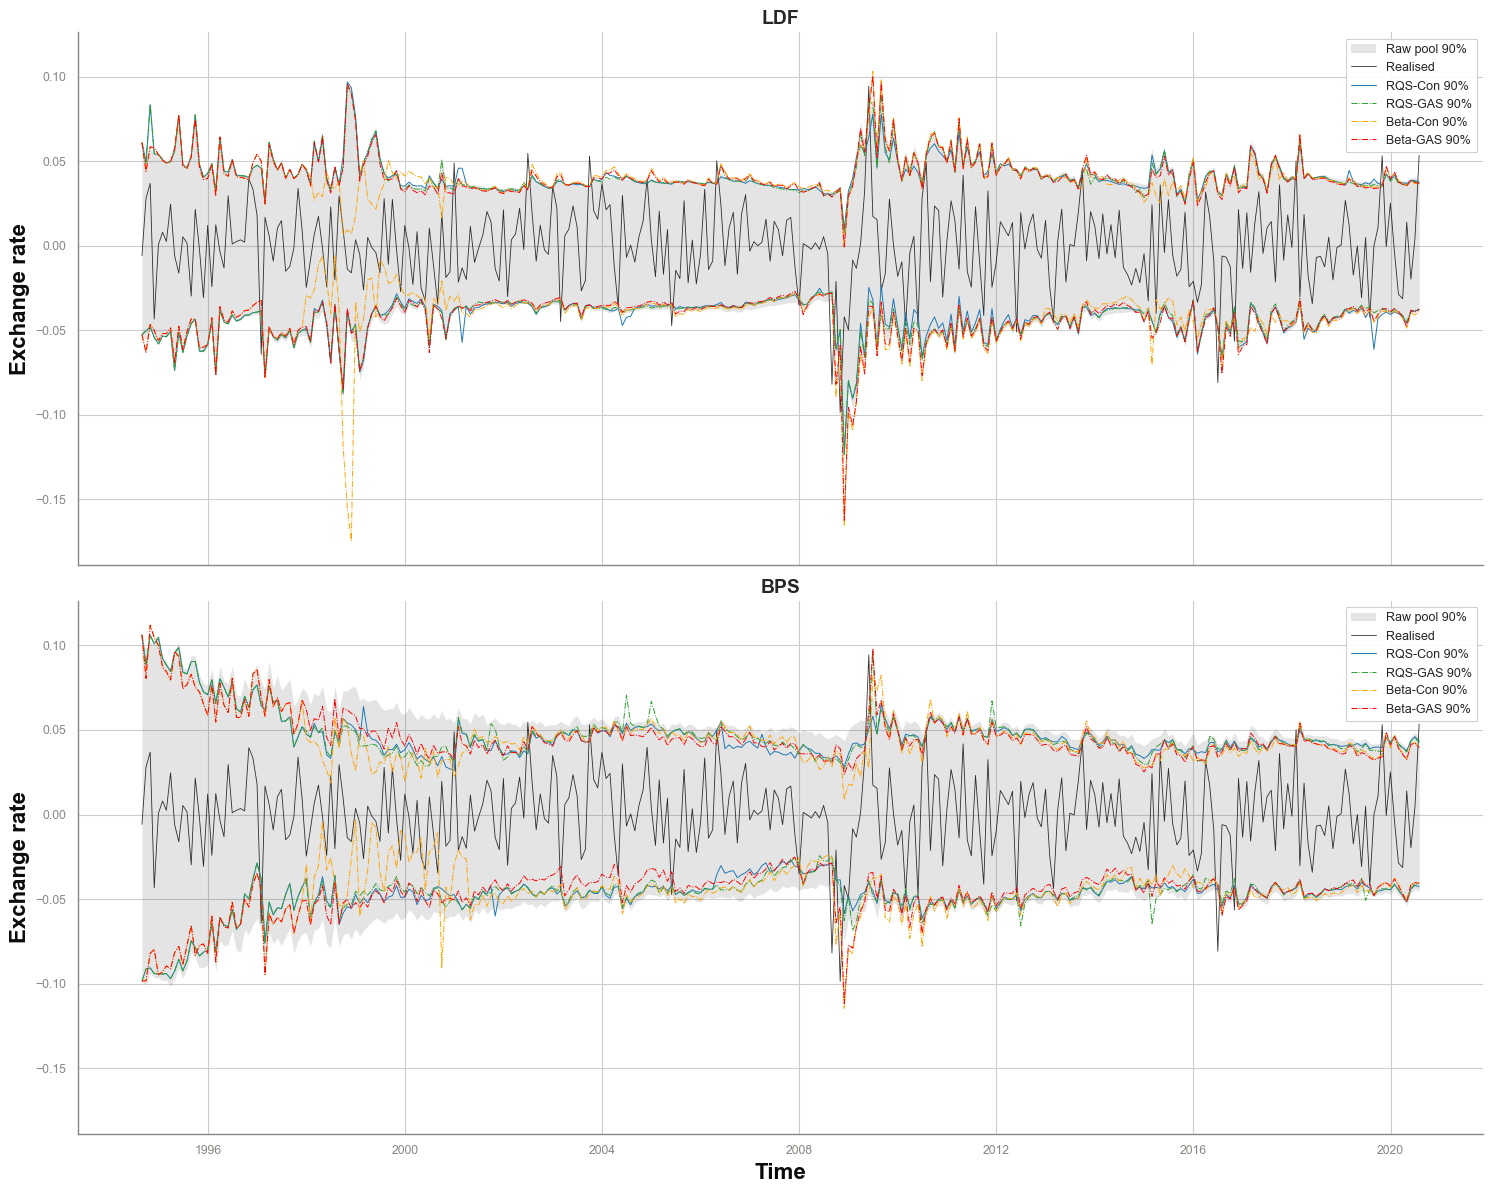

--- LDF ---
RQS-Con          coverage  92.3% (raw  94.2%)   mean width 0.0858 = 95.8% of raw
RQS-GAS          coverage  92.9% (raw  94.2%)   mean width 0.0859 = 95.9% of raw
Beta-Con         coverage  89.4% (raw  94.2%)   mean width 0.0845 = 94.4% of raw
Beta-GAS         coverage  92.9% (raw  94.2%)   mean width 0.0863 = 96.4% of raw
--- BPS ---
RQS-Con          coverage  93.9% (raw  97.1%)   mean width 0.0962 = 84.9% of raw
RQS-GAS          coverage  92.6% (raw  97.1%)   mean width 0.0966 = 85.3% of raw
Beta-Con         coverage  91.3% (raw  97.1%)   mean width 0.0936 = 82.6% of raw
Beta-GAS         coverage  92.9% (raw  97.1%)   mean width 0.0947 = 83.6% of raw


In [35]:
fig, axes = plt.subplots(2, 1, figsize=(15, 12), sharex=True, sharey=True)
for ax, name in zip(axes, POOLS):
    R = RECAL[name]; es_ = R["rc"][index]["eval_start"]; sl = slice(es_, len(dates))
    ax.fill_between(dates[sl], np.asarray(R["rc"][index]["y_raw_q05"])[sl], np.asarray(R["rc"][index]["y_raw_q95"])[sl],
                    color="#4d4d4d", alpha=0.15, linewidth=0, label="Raw pool 90%")
    ax.plot(dates[sl], y[sl], color="black", linewidth=0.6, alpha=0.8, label="Realised")
    for k, lab, col, ls in [("rc", "RQS-Con", "#1f77b4", "-"), ("rg", "RQS-GAS", "#2ca02c", "-."),
                            ("bc", "Beta-Con", "orange", "-."), ("bg", "Beta-GAS", "red", "-.")]:
        ax.plot(dates[sl], np.asarray(R[k][index]["y_calibrated_q05"])[sl], color=col, linestyle=ls, linewidth=0.7,
                label=f"{lab} 90%")
        ax.plot(dates[sl], np.asarray(R[k][index]["y_calibrated_q95"])[sl], color=col, linestyle=ls, linewidth=0.7)
    ax.set_title(name, fontsize=14, fontweight="bold")
    ax.legend(fontsize=9, loc="upper right", frameon=True, framealpha=0.9, edgecolor="0.8", fancybox=False)
    ax.set_ylabel("Exchange rate", fontsize=16, fontweight="bold")
axes[-1].set_xlabel("Time", fontsize=16, fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "bps_vs_ldf_intervals_recal.png", dpi=300, bbox_inches="tight"); plt.show()


def interval_summary(d, y, sl, name):
    lo, hi = np.asarray(d[index]["y_calibrated_q05"])[sl], np.asarray(d[index]["y_calibrated_q95"])[sl]
    lo_r, hi_r = np.asarray(d[index]["y_raw_q05"])[sl], np.asarray(d[index]["y_raw_q95"])[sl]
    yy = np.asarray(y)[sl]
    cov = float(np.mean((yy >= lo) & (yy <= hi)))
    cov_raw = float(np.mean((yy >= lo_r) & (yy <= hi_r)))
    w, w_raw = float(np.mean(hi - lo)), float(np.mean(hi_r - lo_r))
    print(f"{name:16s} coverage {cov:6.1%} (raw {cov_raw:6.1%})   "
          f"mean width {w:.4f} = {w / w_raw:5.1%} of raw")


for pool in POOLS:
    R = RECAL[pool]; sl = slice(R["rc"][index]["eval_start"], len(dates))
    print(f"--- {pool} ---")
    for nm, k in [("RQS-Con", "rc"), ("RQS-GAS", "rg"), ("Beta-Con", "bc"), ("Beta-GAS", "bg")]:
        interval_summary(R[k], y, sl, nm)

## 5. Localized metrics

In [24]:
LOC = {}
for name, P in POOLS.items():
    R = RECAL[name]
    print(f"\n==================== {name} ====================")
    LOC[name] = evaluate_localized(
        x=x_grid, y=y, pit_data=P["pits"], cdf_data=P["cdfs"],
        methods={"GAS spline": R["rg"], "CONV spline": R["rc"], "GAS beta": R["bg"], "CONV beta": R["bc"]},
        discount_factor=P["label"][0], eval_start=eval_start, min_events=55, n_blocks=4)


==================== LDF ====================

LOCALIZED EVALUATION   base pool = pit_data row 0   discount factor 0.9
  window [0,312)   n=312   offset 0   max |PIT_grid - PIT_stored| = 0.00e+00
  regions (rolling 48 thresholds, n=312, min_events=55): tails q=0.2, 4 blocks
    realised counts -> left tail  q=0.2:72, right tail q=0.8:63, left tail  q=0.33:106, right tail q=0.67:106, block 1/4:85, block 2/4:75, block 3/4:72, block 4/4:80

INPUT CHECKS
[discount factor 0.9   window [0,312)   n=312]
                               value
pool row                           0
offset                             0
window                       [0,312)
n                                312
max |PIT_grid - PIT_stored|   0.0000
KS PIT stored                 0.0559
KS PIT grid                   0.0559
grid mass                     1.0000
obs outside grid              0.0000

MASTER TABLE -- levels  (delta = gain over the raw pool, POSITIVE ALWAYS MEANS BETTER; HAC t-stat stars)
[discount factor 0.9 

In [25]:
pickle.dump({"recal": RECAL, "pools": POOLS, "bps_out": bps_out, "loc": LOC}, open(f"results/bps_vs_ldf_fx_{ccy}.pkl", "wb"))